# Lab 16: How a coding agent edits files and runs tests

## Goal

Build a small coding agent and judge its work by what it leaves on disk. A model cannot open a file: it replies with
text, or with a request for a tool, and our code does the reading, the writing and the test runs. We start with a
to-do list the model cannot see, give it two file tools, and then a bill-splitting function whose test fails. The
agent's first fix looks right and still fails, and the test report our code sends back shows it what the fix
missed. Then we take the same agent to the Chinook music shop's pricing code, with the shop's rules in an
`AGENTS.md` file, a check on every file name, and our own checks of the result. The last part shows what that
check cannot stop: running the tests runs whatever code the model wrote, on your machine.

## What you will learn

- How a model works on files it cannot open: file tools as plain Python functions, described to the model as
  schemas and run by our loop.
- How a test report guides the agent: the failure our code returns tells the model what its first fix missed.
- How to keep file tools inside one folder with a path check (`resolve()` and `is_relative_to()`).
- How coding agents load a project's rules from `AGENTS.md` into their instructions.
- How to judge an agent's change on disk: the patch, your own test run, the tests unchanged, the rules followed.
- Why running the tests runs the model's code, and what a path check does not stop.

## Setup

The first cell is the same in every lab: it finds the repository folder by `models.env`, reads the model name and
the reasoning effort from there, and takes your key from `.env` without printing it.

In [1]:
from pathlib import Path
import os
from dotenv import dotenv_values

# The repository folder is the first folder, from here upwards, that holds models.env
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "models.env").exists())

# Models and prices come from models.env; a non-empty value in .env replaces one of them
settings = dotenv_values(ROOT / "models.env")
local = dotenv_values(ROOT / ".env")
settings.update({name: value for name, value in local.items() if name in settings and value})

# The key comes from the environment or .env, and is never printed
os.environ.setdefault("OPENAI_API_KEY", local.get("OPENAI_API_KEY") or "")
assert os.environ["OPENAI_API_KEY"], "Put OPENAI_API_KEY in .env at the repository folder (copy .env.example)."

MODEL = settings["MODEL_DEFAULT"]
EFFORT = settings["REASONING_EFFORT"] or None
print("model:", MODEL, "| reasoning effort:", EFFORT, "| key found: yes")

model: gpt-6-luna | reasoning effort: none | key found: yes


Next, one client for the whole notebook and the names this lab uses:

- `timeout=60`: a request that gets no answer fails after 60 seconds instead of the client's default of ten
  minutes.
- `WORK` is `workspace/`, the folder every agent in this lab works in. Git ignores it.
- `MAX_OUTPUT` caps each reply at 800 tokens, enough room for a whole small file in one write.

Every model call passes `reasoning_effort=EFFORT or omit`. With effort `none`, as `models.env` sets it, this model
can call tools on Chat Completions, the API this lab uses; `omit` leaves the argument out for a model that takes no
effort setting.

In [2]:
import json
import shutil
import subprocess
import sys
import textwrap
from openai import OpenAI, omit

client = OpenAI(timeout=60)
LAB = ROOT / "16_Coding_Agent"
WORK = LAB / "workspace"   # the folder the agent works in; git ignores it
MAX_OUTPUT = 800           # tokens per reply

---

## Part A: Ask a model to tidy a file it cannot see

You have probably asked an assistant in your editor to "fix this" or "clean up that file", and watched the file
change. It looks as if the model opened the file and typed. Before any tool, we check what a model can do with a
file when the request holds nothing but text.

Every part of this lab starts the same way: we delete `workspace/` and copy a start folder in its place, so every
run starts from the same files. `shutil.rmtree(WORK, ignore_errors=True)` deletes the folder with everything in it
(and does nothing when it is not there yet); `shutil.copytree(start, WORK)` copies the start folder in its place.
The first start folder is `practice_start/`.

⚠️ `rmtree` deletes a whole folder without asking. Here it only ever deletes the lab's own `workspace/`; never point
`WORK` at a folder that holds your own files.

In [3]:
def fresh_workspace(start):
    """Delete workspace/ and copy the start folder in its place."""
    shutil.rmtree(WORK, ignore_errors=True)
    shutil.copytree(start, WORK)


fresh_workspace(LAB / "practice_start")
print(sorted(p.name for p in WORK.iterdir()))

['split_bill.py', 'test_split_bill.py', 'todo.txt']


Three files. Parts A and B use the first, `todo.txt`; Part C uses the other two. Here is the to-do list:

In [4]:
print((WORK / "todo.txt").read_text())

buy milk
call the dentist
Buy milk
water the plants
  pay the electricity bill
call the dentist
water the plants
book train tickets for Friday



Eight lines and only five tasks: *buy milk* appears twice (once with a capital B), *call the dentist* twice,
*water the plants* twice, and *pay the electricity bill* starts with two spaces.

We ask the model to tidy it. The request holds a system message and the task, and nothing else: no tools and no
file.

In [5]:
SYSTEM = "You help with the files in a small folder on the user's computer."
TASK = "Tidy todo.txt and remove the duplicates."

response = client.chat.completions.create(
    model=MODEL,
    messages=[{"role": "system", "content": SYSTEM}, {"role": "user", "content": TASK}],
    max_completion_tokens=MAX_OUTPUT,
    reasoning_effort=EFFORT or omit,
)
print(response.choices[0].message.content)

I don’t see a `todo.txt` file attached or available here. Upload it or paste its contents, and I’ll tidy it and remove duplicate entries.


The reply says there is no `todo.txt` attached or available, and asks us to upload the file or paste its
contents. Nothing was tidied, and nothing on disk changed.

The model generates its reply from the request and from the text it was trained on. `todo.txt` is in neither. It sits on our disk, and nothing in this request can read it or write it. To change the file, the model
needs something that can, and that something has to be our code.

**Checkpoint A.** Three files in `workspace/`; the to-do list has eight lines and five tasks; with no tools, the
reply asks for the file (ours: *Upload it or paste its contents*) and `todo.txt` is unchanged.

---

## Part B: Give the model two file tools, and watch the file change

The model cannot open a file, but it can ask our code to. This part gives it two tools, and our code runs them.

The tools are plain Python functions. Each one returns a **string**, because a tool's result goes back to the model
as the text of a message.

- `read_file(path)` returns the text of one file in `workspace/`. When there is no such file, it returns a
  sentence that says so, which the model can read, instead of raising an error.
- `write_file(path, content)` replaces the **whole** file with `content` (and creates it if it is missing). It is
  the simplest edit tool there is; Part F shows what coding agents send instead.

`WORK / path` joins the folder and the file name into one path.

In [6]:
def read_file(path):
    """The text of one file in the workspace."""
    target = WORK / path
    if not target.is_file():
        return f"There is no file named {path} in the workspace."
    return target.read_text()


def write_file(path, content):
    """Replace the whole file with content; create it if it is missing."""
    (WORK / path).write_text(content)
    return f"Wrote {len(content)} characters to {path}."

**Important:** these two functions accept any file name. Part D adds a check before the agent works on anything
that matters.

We call them ourselves first, the way the model will: a file that is not there, then a small write, then the
folder's file names.

In [7]:
print(read_file("shopping.txt"))
print(write_file("hello.txt", "hello\n"))
print(sorted(p.name for p in WORK.iterdir()))

There is no file named shopping.txt in the workspace.
Wrote 6 characters to hello.txt.
['hello.txt', 'split_bill.py', 'test_split_bill.py', 'todo.txt']


`read_file("shopping.txt")` returned a sentence, not an error. `write_file` wrote 6 characters (`hello` and a line
break), and `hello.txt` is now in the folder. The agent's run below starts from a fresh copy, so this file will be
gone.

### Describe the two tools to the model

**The model never sees our Python.** It sees a description of each tool, a **schema**, sent in `tools=[...]`:

- `name`: what the model writes to ask for the tool.
- `description`: what the tool is for. The model chooses tools by reading this.
- `parameters`: the arguments, as a JSON Schema. `read_file` takes one string, `path`; `write_file` takes `path`
  and `content`.
- `strict: True`: the arguments the model writes must match the schema exactly. Strict mode needs every argument
  listed in `required` and `additionalProperties` set to `False`.

`FILE_FUNCTIONS` maps each tool name to the Python function allowed to run for it; the loop below receives it as
`functions`. Only the functions in that dictionary can run: the model can ask only for the names in `tools`, and any
other name would stop the loop with a `KeyError`.

In [8]:
READ_SCHEMA = {
    "type": "function",
    "function": {
        "name": "read_file",
        "description": "Read one file in the folder.",
        "strict": True,
        "parameters": {
            "type": "object",
            "properties": {"path": {"type": "string", "description": "A file name, for example 'todo.txt'"}},
            "required": ["path"],
            "additionalProperties": False,
        },
    },
}
WRITE_SCHEMA = {
    "type": "function",
    "function": {
        "name": "write_file",
        "description": "Replace the whole content of one file in the folder (creates it if missing).",
        "strict": True,
        "parameters": {
            "type": "object",
            "properties": {
                "path": {"type": "string", "description": "A file name, for example 'todo.txt'"},
                "content": {"type": "string"},
            },
            "required": ["path", "content"],
            "additionalProperties": False,
        },
    },
}

FILE_TOOLS = [READ_SCHEMA, WRITE_SCHEMA]
FILE_FUNCTIONS = {"read_file": read_file, "write_file": write_file}

### The loop that runs the tools

The agent loop: our code calls the model, runs every tool the model asks for, sends the results back, and repeats
until the model answers in text. Each pass is one **turn**, one call to the model:

1. Send the whole message list, with the tool schemas.
2. Add the model's reply to the list.
3. If `finish_reason` is not `tool_calls`, the reply is the answer: print it and stop.
4. Otherwise, for every tool call in the reply: turn its arguments (a JSON string) into a dictionary with
   `json.loads`, look the name up in `functions`, call the function with `**args` (each key becomes a keyword
   argument: `read_file(path="todo.txt")`), and add the result to the list as a `tool` message with the call's
   `id`. Then go back to step 1.

`for turn in range(1, max_turns + 1)` is a **turn cap**: the loop stops after 15 turns, whatever the model still
asks for, and then returns with no answer.

So that we can follow a run, the loop prints one line per tool call: the turn, the tool and the file name. Under a
`write_file` it prints the new file, indented four spaces by `textwrap.indent`. Under a `run_tests` it prints the
lines of the test report that matter, for us to read; the model gets the whole report, the same text we print by
hand in Part C. That tool does not exist yet: Part C adds it. The function returns the whole
message list, so we can read the run again afterwards.

In [9]:
def run_agent(system, task, tools, functions, max_turns=15):
    messages = [{"role": "system", "content": system}, {"role": "user", "content": task}]
    for turn in range(1, max_turns + 1):
        response = client.chat.completions.create(
            model=MODEL, messages=messages, tools=tools,
            max_completion_tokens=MAX_OUTPUT, reasoning_effort=EFFORT or omit,
        )
        reply = response.choices[0].message
        messages.append(reply)
        if response.choices[0].finish_reason != "tool_calls":
            print(f"turn {turn}: answer: {reply.content}")
            return messages
        for call in reply.tool_calls:
            args = json.loads(call.function.arguments)
            result = functions[call.function.name](**args)
            messages.append({"role": "tool", "tool_call_id": call.id, "content": result})
            print(f"turn {turn}: {call.function.name}({args.get('path', '')})")
            if call.function.name == "write_file":
                print(textwrap.indent(args["content"].rstrip(), "    "))
            if call.function.name == "run_tests":
                report = [line for line in result.splitlines() if line.startswith(("AssertionError", "OK", "FAILED"))]
                print(textwrap.indent("\n".join(report), "    "))
    print("turn cap reached: no answer")
    return messages

The same system message and task as in Part A, from a fresh copy of the folder, and now with the two tools. Before
you run it: how many tool calls will the model need?

In [10]:
fresh_workspace(LAB / "practice_start")
messages = run_agent(SYSTEM, TASK, FILE_TOOLS, FILE_FUNCTIONS)

turn 1: read_file(todo.txt)


turn 2: write_file(todo.txt)
    buy milk
    call the dentist
    water the plants
    pay the electricity bill
    book train tickets for Friday


turn 3: answer: Tidied `todo.txt` and removed duplicates, treating “buy milk” and “Buy milk” as the same task.


Two tool calls and an answer, in three turns:

- **Turn 1:** `read_file(todo.txt)`. Our code read the file and sent its eight lines back as the tool's result.
- **Turn 2:** `write_file(todo.txt)`, with the new list as `content`: the five lines printed under the call. Our
  code wrote them to disk.
- **Turn 3:** the answer, in text: *Tidied `todo.txt` and removed duplicates, treating “buy milk” and “Buy milk” as
  the same task.*

The model wrote the new list; our code put it on disk. Here is the file, read from the disk, not from the model's
reply:

In [11]:
print((WORK / "todo.txt").read_text())

buy milk
call the dentist
water the plants
pay the electricity bill
book train tickets for Friday



Five lines, one per task. The repeated lines are gone, *Buy milk* with its capital B was taken as the same
task as *buy milk*, and the two spaces before *pay the electricity bill* are gone. Merging the two milk lines and
removing the spaces were the model's reading of "tidy"; the task did not ask for either.

**Key lesson:** the model asked, and our code acted. Every change on disk was made by `write_file`, a function we
wrote, called with arguments the model wrote. That is what a coding agent is: the agent loop, with file tools,
pointed at a folder.

**Checkpoint B.** `read_file(todo.txt)`, then `write_file(todo.txt)`, then an answer, in three turns; `todo.txt` on disk
has five lines, one per task.

---

## Part C: Fix a failing test, and see how the test report leads to the second fix

A coding agent is usually given a test to pass. The test says what "fixed" means, and the agent can run it as often
as it likes. This part adds that third tool.

The other two files in the folder are a small function and its test. A fresh copy first, then both files:

In [12]:
fresh_workspace(LAB / "practice_start")
for name in ["split_bill.py", "test_split_bill.py"]:
    print(f"----- {name}")
    print((WORK / name).read_text())

----- split_bill.py
def split_bill(total, people):
    """Each person's share when a bill is split evenly."""
    return total * people

----- test_split_bill.py
import unittest

from split_bill import split_bill


class SplitBillTest(unittest.TestCase):
    def test_two_friends(self):
        self.assertEqual(split_bill(50, 2), 25)

    def test_three_friends(self):
        self.assertEqual(split_bill(60.30, 3), 20.10)



Reading the two files:

- **`split_bill.py`** has one function, `split_bill(total, people)`: each person's share when friends split a bill.
  It returns `total * people`: it **multiplies** where it should divide.
- **`test_split_bill.py`** is a `unittest` test case with two tests. Each method whose name starts with `test_` is
  one test, and `assertEqual(a, b)` fails the test when `a` and `b` differ.
  - `test_two_friends`: a bill of 50 split between two is 25 each.
  - `test_three_friends`: a bill of 60.30 split between three is **20.10** each.

To run the tests we start a second Python process, the way you would in a terminal. `subprocess.run` takes the
command as a list of words:

- `sys.executable` is the Python running this notebook, so the tests run with the same Python and packages;
- `-m unittest -v` runs the standard library's test runner, which finds every `test_*.py` file in the current
  folder and, with `-v`, prints one line per test;
- `cwd=WORK` starts the new process in `workspace/`, so `from split_bill import split_bill` finds the workspace's
  file;
- `capture_output=True, text=True` keeps what the process prints, as strings, instead of showing it;
- `timeout=30` stops the process if it has not finished after 30 seconds.

`unittest` writes its report to `stderr`, the second output stream; a `print()` in the code under test goes to
`stdout`. We print both. The report names each file by its full path on your machine, so we replace the
workspace's path with the word `workspace`.

In [13]:
result = subprocess.run(
    [sys.executable, "-m", "unittest", "-v"],
    cwd=WORK, capture_output=True, text=True, timeout=30,
)
print("exit code:", result.returncode)
print((result.stdout + result.stderr).replace(str(WORK.resolve()), "workspace"))

exit code: 1
test_three_friends (test_split_bill.SplitBillTest.test_three_friends) ... FAIL
test_two_friends (test_split_bill.SplitBillTest.test_two_friends) ... FAIL

FAIL: test_three_friends (test_split_bill.SplitBillTest.test_three_friends)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "workspace/test_split_bill.py", line 11, in test_three_friends
    self.assertEqual(split_bill(60.30, 3), 20.10)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: 180.89999999999998 != 20.1

FAIL: test_two_friends (test_split_bill.SplitBillTest.test_two_friends)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "workspace/test_split_bill.py", line 8, in test_two_friends
    self.assertEqual(split_bill(50, 2), 25)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: 100 != 25

----------------------------------------------------------------------
Ran 2

Reading the report:

- Both tests `FAIL`, and the report ends `FAILED (failures=2)`. Exit code 1: anything other than 0 means
  something failed.
- `AssertionError: 100 != 25`: with the bug, 50 × 2 is 100.
- `AssertionError: 180.89999999999998 != 20.1`: 60.30 × 3, with a long tail of digits we come back to below.

The third tool, `run_tests`, is that call inside a function. It returns the report as one string, so the model can
read it, and if the 30 seconds run out, `subprocess.run` raises `subprocess.TimeoutExpired`; `try` / `except` catches it and
returns a sentence instead. A loop that never ends is one of the bugs a model can write.

⚠️ `run_tests` runs whatever code is in `workspace/`, as you, on your machine. Here that is code the model writes.
Part G shows what that means.

In [14]:
def run_tests():
    """Run the unit tests in the workspace and return the report as text."""
    try:
        result = subprocess.run(
            [sys.executable, "-m", "unittest", "-v"],
            cwd=WORK, capture_output=True, text=True, timeout=30,
        )
    except subprocess.TimeoutExpired:
        return "The tests did not finish within 30 seconds and were stopped."
    return (result.stdout + result.stderr).replace(str(WORK.resolve()), "workspace")

Its schema takes no arguments, so `properties` is empty. The system message now says how to work on code: read
before changing anything, run the tests after every change, stop when they pass. It does not say what the bug is.
The task is one sentence.

In [15]:
TESTS_SCHEMA = {
    "type": "function",
    "function": {
        "name": "run_tests",
        "description": "Run the unit tests in the folder and return their report.",
        "strict": True,
        "parameters": {"type": "object", "properties": {}, "required": [], "additionalProperties": False},
    },
}

CODE_TOOLS = [READ_SCHEMA, WRITE_SCHEMA, TESTS_SCHEMA]
CODE_FUNCTIONS = {"read_file": read_file, "write_file": write_file, "run_tests": run_tests}
CODE_SYSTEM = ("You fix Python code in a small folder. Read the failing test and the code before you change "
               "anything, and run the tests after every change. When the tests pass, stop and say in one or two "
               "sentences what you changed.")
CODE_TASK = "The tests in test_split_bill.py fail. Make them pass."

Before you run it: what will the agent's first fix be, and will it pass?

In [16]:
fresh_workspace(LAB / "practice_start")
messages = run_agent(CODE_SYSTEM, CODE_TASK, CODE_TOOLS, CODE_FUNCTIONS)

turn 1: read_file(test_split_bill.py)
turn 1: read_file(split_bill.py)


turn 2: run_tests()
    AssertionError: 180.89999999999998 != 20.1
    AssertionError: 100 != 25
    FAILED (failures=2)


turn 3: write_file(split_bill.py)
    def split_bill(total, people):
        """Each person's share when a bill is split evenly."""
        return total / people


turn 4: run_tests()
    AssertionError: 20.099999999999998 != 20.1
    FAILED (failures=1)


turn 5: write_file(split_bill.py)
    def split_bill(total, people):
        """Each person's share when a bill is split evenly."""
        return round(total / people, 2)


turn 6: run_tests()
    OK


turn 7: answer: Updated `split_bill` to divide the total by the number of people and round the result to two decimal places. All tests pass.


Read the run turn by turn:

- **Turn 1:** two reads in one reply, the test and the code.
- **Turn 2:** `run_tests` before changing anything: the two failures we saw by hand.
- **Turn 3:** the first write. `total * people` becomes `total / people`. That fixes the bug as anyone would read
  it.
- **Turn 4:** `run_tests` again: `AssertionError: 20.099999999999998 != 20.1` and `FAILED (failures=1)`. One test
  passes now; the other still fails, by a tiny amount.
- **Turn 5:** the second write: the same line inside `round(..., 2)`.
- **Turn 6:** `run_tests`: `OK`.
- **Turn 7:** the answer: *Updated `split_bill` to divide the total by the number of people and round the result
  to two decimal places. All tests pass.*

**Why did the first fix fail?** On paper, 60.30 ÷ 3 is exactly 20.10. Python stores a number such as 60.30 in
binary, and most decimal fractions have no exact binary form, the way 1/3 has no exact decimal form. The stored
number is a tiny bit off, and so is the result of the division. Two lines show it:

In [17]:
print(60.30 / 3)
print(round(60.30 / 3, 2))

20.099999999999998
20.1


`60.30 / 3` is `20.099999999999998`, and `round(..., 2)` turns it into `20.1`, which equals the test's `20.10`.
Code that handles money rounds to cents, or counts in whole cents, so that a tail like this never reaches a price.

Nothing in `split_bill.py` says the first fix is wrong. The test report said so: `AssertionError: 20.099999999999998 != 20.1` reached the model as the text our `run_tests` returned, and
the second write followed from it. Without a test run between the two writes, nothing in the loop would have shown
that the first fix was wrong.

**Try it:** give the agent a test that wants `split_bill(100, 3) == 33.33` instead. In a new cell:

```python
fresh_workspace(LAB / "practice_start")
test = (WORK / "test_split_bill.py").read_text()
(WORK / "test_split_bill.py").write_text(test.replace("split_bill(60.30, 3), 20.10", "split_bill(100, 3), 33.33"))
messages = run_agent(CODE_SYSTEM, CODE_TASK, CODE_TOOLS, CODE_FUNCTIONS)
```

When we tried it, the model rounded on its first write: `33.33` in the test already shows a rounded number.

**Checkpoint C.** By hand, both tests fail (`AssertionError: 100 != 25` and `180.89999999999998 != 20.1`). In the agent's
run: a first write of `total / people`, then `AssertionError: 20.099999999999998 != 20.1`, a second write with
`round(..., 2)`, `OK` and an answer (ours: 7 turns). `60.30 / 3` prints `20.099999999999998`.

---

## The Chinook shop's code

Now we point the same agent at a shop's real code. Chinook is an online music shop that sells tracks and albums.
Its developers keep their code in a folder: a pricing function with a bug, its test, and a file of rules for coding
agents, `AGENTS.md`. The start folder is `workspace_start/`; we copy it to `workspace/` as before.

Three things change from the to-do list and the bill. The folder sits inside a repository, two folders below the
`.env` file that holds our key. The shop has rules that no test checks. And the shop will want to know what the
agent changed, not only that the tests pass. The picture shows the agent we build for it:

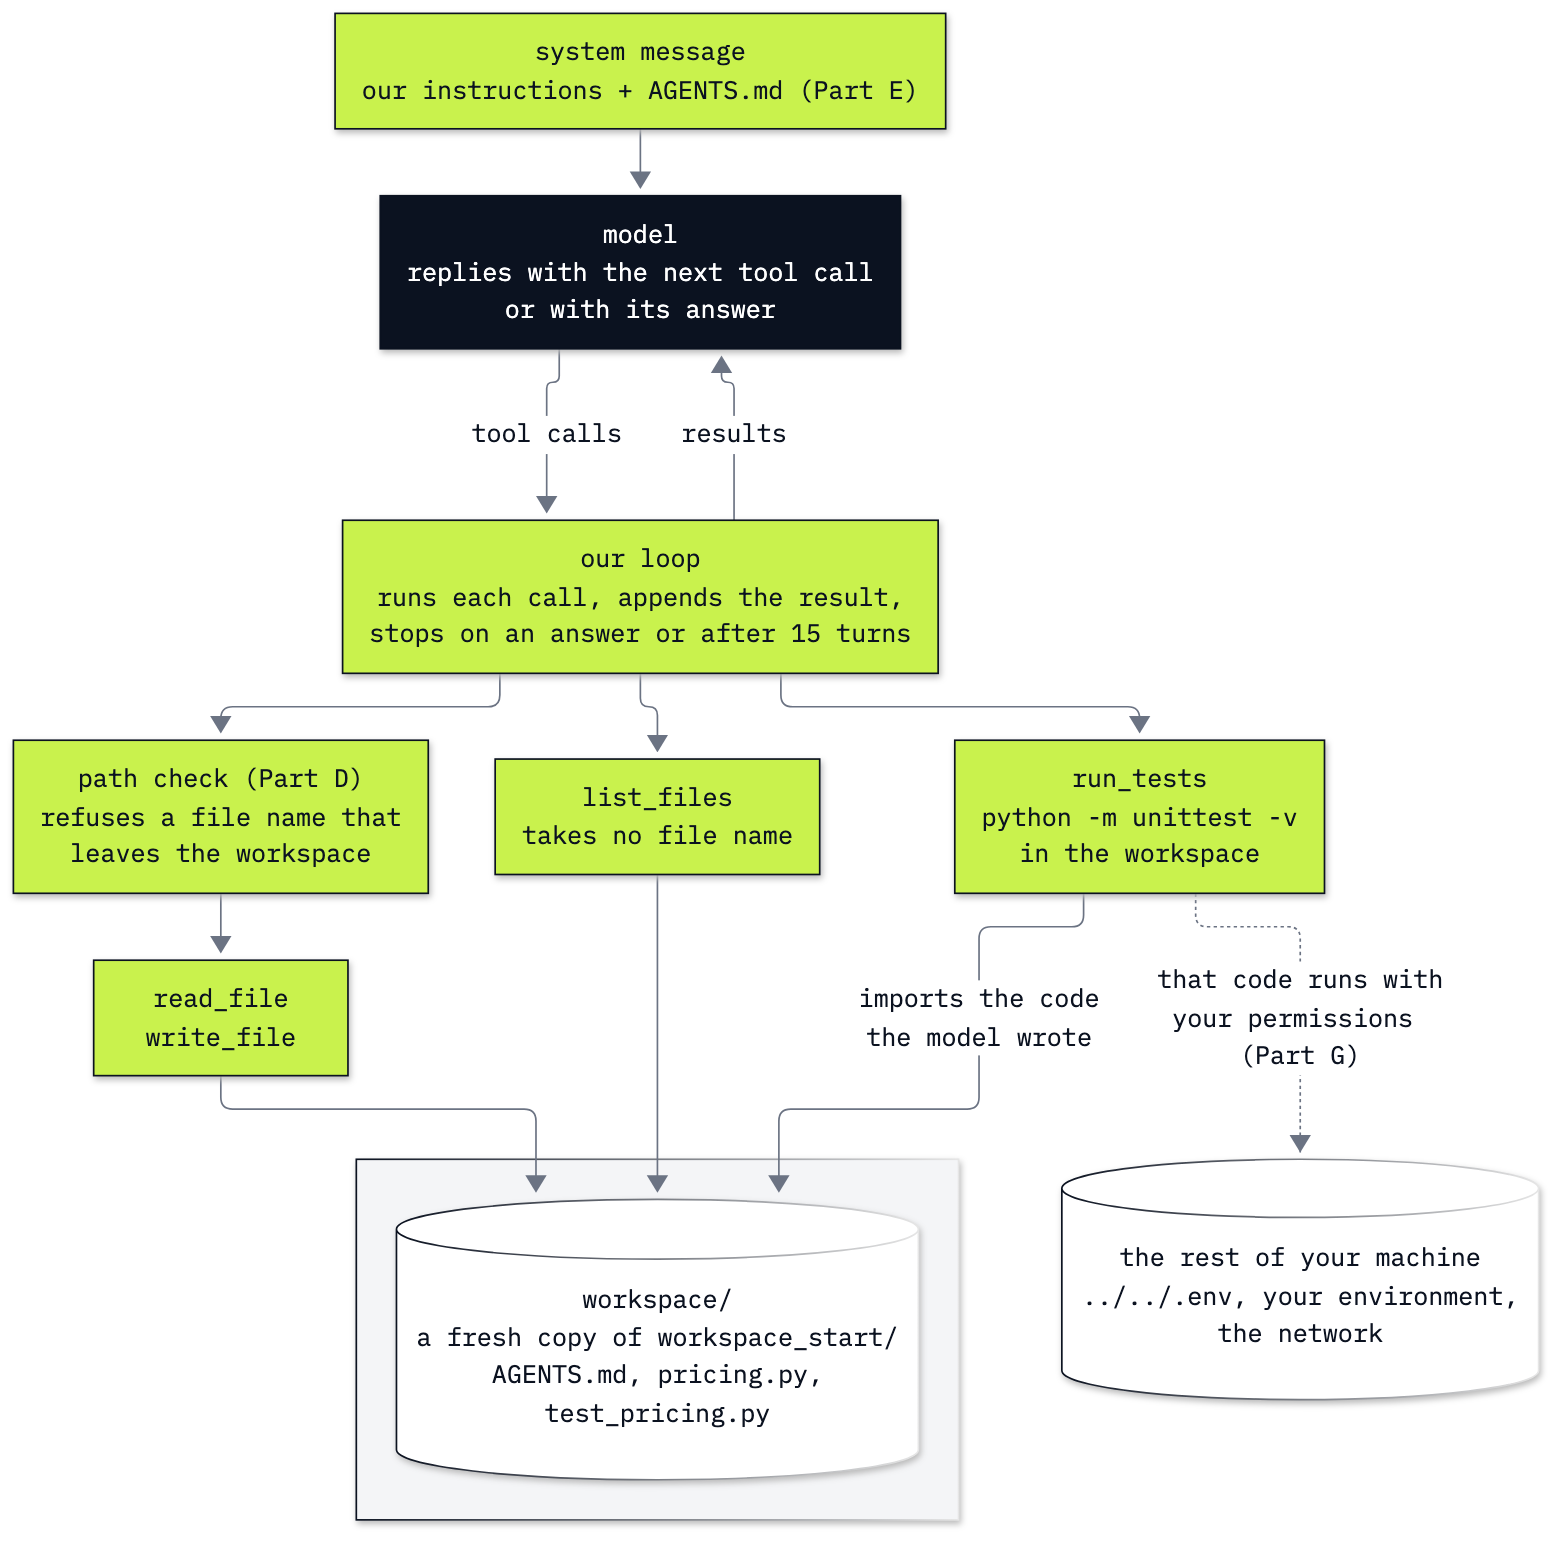

In [18]:
from IPython.display import Image

Image("resources/lab16_coding_agent.png", width=760)

How to read the picture:

- The dark box is the model's step: it replies with the next tool call or with its answer. The lime boxes are our
  code, the file tools included. The white cylinders are what the code can reach: `workspace/` inside the grey box, and outside it the rest of your machine, which the figure lists as `../../.env`, your environment and the network.
- At the top, our code builds the system message from our instructions and the shop's `AGENTS.md` (Part E).
- On the left, every file name the model writes goes through a **path check** before `read_file` or `write_file`
  touches the disk (Part D). In the middle, `list_files` takes no file name and lists only `workspace/`.
- On the right, `run_tests` takes no file name. It runs Python on whatever the files hold. The dashed line leaves
  the workspace (Part G).

---

## Part D: Keep the file tools inside the workspace with a path check

In Parts B and C the model chose every file name: `todo.txt`, `split_bill.py`. A file name is text the model wrote,
and our `read_file` takes any text. `workspace/` sits two folders below the repository folder, where `.env` holds
our key, so `../../.env` (`..` means one folder up) is a file name `read_file` would open.

First, what a file name turns into. `WORK / name` joins two paths. `.resolve()` turns the result into the full path
it really points to: it removes every `..` and follows links. And when the name is already a full path, such as
`/etc/hosts`, `WORK /` drops the folder altogether. `is_relative_to(folder)` answers one question: is this path
inside that folder?

We print each resolved path relative to the repository folder, or "outside the repository", so no folder from your
machine appears.

In [19]:
START = LAB / "workspace_start"
fresh_workspace(START)

for name in ["pricing.py", "../../.env", "/etc/hosts"]:
    target = (WORK / name).resolve()
    where = target.relative_to(ROOT.resolve()) if target.is_relative_to(ROOT.resolve()) else "outside the repository"
    print(f"{name:12} -> {str(where):36} inside workspace/: {target.is_relative_to(WORK.resolve())}")

pricing.py   -> 16_Coding_Agent/workspace/pricing.py inside workspace/: True
../../.env   -> .env                                 inside workspace/: False
/etc/hosts   -> outside the repository               inside workspace/: False


Line by line:

- `pricing.py` resolves to `16_Coding_Agent/workspace/pricing.py`: inside.
- `../../.env` resolves to `.env`, the key file at the repository folder: outside.
- `/etc/hosts` is a system file: outside the repository altogether.

Resolving first and then asking where the path ends up is the reliable order. A check on the text of the name
("does it contain `..`?") misses a full path such as `/etc/hosts`, which has no `..` at all, and a link inside the
folder that points outside it, which `resolve()` follows.

The check is that one question, in a function the file tools call before they touch a file:

In [20]:
def check_path(name):
    """The file inside the workspace that name points to, or None when name leaves the workspace."""
    target = (WORK / name).resolve()
    if target.is_relative_to(WORK.resolve()):
        return target
    return None


for name in ["pricing.py", "../../.env", "/etc/hosts"]:
    print(f"{name:12} -> {'allowed' if check_path(name) else 'refused'}")

pricing.py   -> allowed
../../.env   -> refused
/etc/hosts   -> refused


`check_path` returns the resolved path when it is inside the workspace and `None` when it is not.

Now the file tools for the shop. `read_file` and `write_file` are Part B's functions with the check first: a name
that leaves the workspace gets a refusal **sentence**, so the model can read why and try something else. And one
new tool, `list_files`, because the shop's task will not name any file: it returns the names of the files in the
workspace, one per line.

The new functions replace Part B's under the same names. `FILE_FUNCTIONS` and `CODE_FUNCTIONS` still point to
Part B's unchecked functions: a dictionary holds the function it was given, not its name. That is why Part E builds
a new one.

In [21]:
def list_files():
    """The names of the files in the workspace, one per line."""
    return "\n".join(sorted(p.name for p in WORK.iterdir() if p.is_file()))


def read_file(path):
    """The text of one file in the workspace, or a refusal."""
    target = check_path(path)
    if target is None:
        return f"Refused: {path} is outside the workspace."
    if not target.is_file():
        return f"There is no file named {path} in the workspace."
    return target.read_text()


def write_file(path, content):
    """Replace the whole file with content, or refuse."""
    target = check_path(path)
    if target is None:
        return f"Refused: {path} is outside the workspace."
    target.write_text(content)
    return f"Wrote {len(content)} characters to {path}."

We call them as the model would: the folder's file names, a read outside, a write outside.

In [22]:
print(list_files())
print("-----")
print(read_file("../../.env"))
print(write_file("../notes.txt", "a note"))

AGENTS.md
pricing.py
test_pricing.py
-----
Refused: ../../.env is outside the workspace.
Refused: ../notes.txt is outside the workspace.


`list_files` named the three files in the shop's folder. The read of `../../.env` and the write to `../notes.txt`
(in the lab folder, one level up) both came back as a refusal sentence: nothing was read and nothing was written.

**Important:** the path check looks at **names**. It decides which files the tools may open. It says nothing about
what the code inside an allowed file does when it runs. Part G comes back to that.

**Checkpoint D.** `pricing.py` allowed; `../../.env` and `/etc/hosts` refused; `list_files` gives `AGENTS.md`,
`pricing.py` and `test_pricing.py`; the read and the write outside the workspace come back as refusal sentences.

---

## Part E: Load the shop's rules from AGENTS.md, and fix the pricing bug

A project has rules a test cannot check: how changes are recorded, which files to leave alone. Coding agents read
them from a plain Markdown file at the project's root, `AGENTS.md`. Codex, GitHub Copilot and other coding agents
read it before they start work and add it to their instructions. Here is the shop's:

In [23]:
print((WORK / "AGENTS.md").read_text())

# Instructions for coding agents

- Do not edit the tests. If a test looks wrong, stop and say why.
- Record every fix as one line in CHANGES.md: the file, the function and what you changed.



Two rules: do not edit the tests, and record every fix as one line in `CHANGES.md`. The tests catch a wrong price;
nothing catches a missing line in `CHANGES.md`.

Now the bug. `pricing.py` and its test, and the tests run by us:

In [24]:
for name in ["pricing.py", "test_pricing.py"]:
    print(f"----- {name}")
    print((WORK / name).read_text())
print("-----")
print(run_tests())

----- pricing.py
def apply_discount(price, percent):
    """Price of an item after a percent discount."""
    return price + price * percent / 100

----- test_pricing.py
import unittest

from pricing import apply_discount


class ApplyDiscountTest(unittest.TestCase):
    def test_no_discount(self):
        self.assertEqual(apply_discount(0.99, 0), 0.99)

    def test_ten_percent_off_an_album(self):
        self.assertEqual(apply_discount(9.99, 10), 8.99)

-----
test_no_discount (test_pricing.ApplyDiscountTest.test_no_discount) ... ok
test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album) ... FAIL

FAIL: test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "workspace/test_pricing.py", line 11, in test_ten_percent_off_an_album
    self.assertEqual(apply_discount(9.99, 10), 8.99)
    ~~~~~~~~~~~~~~~~^

Reading the two files and the report:

- **`pricing.py`** has `apply_discount(price, percent)`, which returns `price + price * percent / 100`: it **adds**
  the discount instead of taking it off.
- **`test_pricing.py`**: 0 percent off a 0.99 track is still 0.99; 10 percent off a 9.99 album is **8.99**, what
  the shop charges.
- The report: the first test `ok` (adding 0 percent changes nothing), the second `FAIL` with
  `AssertionError: 10.989 != 8.99`.

Coding agents load `AGENTS.md` with code, not by asking the model to open it: the agent program reads the file and
puts its text in the instructions before the first turn. We do the same, in two lines: read the file, and add it to
the end of Part C's system message.

In [25]:
rules = (WORK / "AGENTS.md").read_text()
SHOP_SYSTEM = CODE_SYSTEM + "\n\nThe workspace's AGENTS.md says:\n" + rules
print(SHOP_SYSTEM)

You fix Python code in a small folder. Read the failing test and the code before you change anything, and run the tests after every change. When the tests pass, stop and say in one or two sentences what you changed.

The workspace's AGENTS.md says:
# Instructions for coding agents

- Do not edit the tests. If a test looks wrong, stop and say why.
- Record every fix as one line in CHANGES.md: the file, the function and what you changed.



The system message is Part C's three sentences, followed by the two rules word for word.

The agent gets four tools: `list_files` (its schema takes no arguments, like `run_tests`'s), and Part C's three.
`SHOP_FUNCTIONS` points to the new, checked `read_file` and `write_file`. The task does not name a file.

In [26]:
LIST_SCHEMA = {
    "type": "function",
    "function": {
        "name": "list_files",
        "description": "List the files in the folder.",
        "strict": True,
        "parameters": {"type": "object", "properties": {}, "required": [], "additionalProperties": False},
    },
}

SHOP_TOOLS = [LIST_SCHEMA, READ_SCHEMA, WRITE_SCHEMA, TESTS_SCHEMA]
SHOP_FUNCTIONS = {"list_files": list_files, "read_file": read_file, "write_file": write_file, "run_tests": run_tests}
SHOP_TASK = "The unit tests in the workspace fail. Make them pass."

From a fresh copy of the shop's folder. Before you run it: 10 percent off 9.99 is 9.99 − 0.999. The first fix
usually turns the `+` into a `-` and nothing more. What will that fix return, and will the test accept it?

In [27]:
fresh_workspace(START)
shop_messages = run_agent(SHOP_SYSTEM, SHOP_TASK, SHOP_TOOLS, SHOP_FUNCTIONS)

turn 1: list_files()


turn 2: read_file(AGENTS.md)
turn 2: read_file(test_pricing.py)
turn 2: read_file(pricing.py)
turn 2: run_tests()
    AssertionError: 10.989 != 8.99
    FAILED (failures=1)


turn 3: write_file(pricing.py)
    def apply_discount(price, percent):
        """Price of an item after a percent discount."""
        return round(price - price * percent / 100, 2)


turn 4: run_tests()
    OK
turn 4: write_file(CHANGES.md)
    - `pricing.py`, `apply_discount`: subtract the percentage discount from the price and round the result to two decimal places.


turn 5: answer: Updated `apply_discount` to subtract the percentage discount and round the result to two decimal places, and recorded the fix in `CHANGES.md`. All unit tests pass.


Read the run turn by turn:

- **Turn 1:** `list_files`. The task names no file, so the model first asks what is there.
- **Turn 2:** four calls in one reply: `AGENTS.md`, the test and the code read, and the tests run, which report
  `AssertionError: 10.989 != 8.99`. The model asked for `AGENTS.md` although its rules were already in the system
  message.
- **Turn 3:** one write of `pricing.py`: `round(price - price * percent / 100, 2)`. The sign is fixed and the result
  rounded in the same write.
- **Turn 4:** two calls in one reply: `run_tests`, which reports `OK`, and `write_file(CHANGES.md)` with one line
  naming the file, the function and the change, as `AGENTS.md` asks.
- **Turn 5:** the answer, which mentions the line in `CHANGES.md`.

**This run rounded on its first write.** That is not what usually happens. In almost every run we made, the first
write was `price - price * percent / 100`, the report said `AssertionError: 8.991 != 8.99`, and the second write
added `round(..., 2)`: the same two steps as the bill in Part C, whose saved run shows them. 9.99 − 0.999 is 8.991,
the exact result of the subtraction, not the tiny binary error from Part C. The 8.99 comes from a rule of the
shop's: it charges in whole cents. Nothing in `pricing.py` says so; only the test does, so in the usual run the rule
reaches the model through the failing test report. Run the cell again and you will probably see the two-step
version.

Either way, the agent's run is only what the model asked for and what it said. Part F reads the disk.

**Checkpoint E.** `AGENTS.md` with its two rules, added to the end of the system message; at the start the tests fail with
`AssertionError: 10.989 != 8.99`; the agent lists the files, reads them, fixes `pricing.py`, gets `OK`, writes
`CHANGES.md` and answers (ours: 5 turns, with the rounding in the first write; usually there are two writes, and
the first fails with `8.991 != 8.99`).

---

## Part F: Judge the change by the files on disk, not by the model's reply

The agent's last message says the tests pass. That sentence is a claim the model wrote. It could be wrong, and the
tests could pass for a bad reason: an agent that edits the test to expect 8.991 also gets green tests. A reviewer
checks a colleague's change by looking at the change and running the tests, and we check the agent's the same way.
Four questions:

1. **What changed?** The file the model sent, and the same change as a patch.
2. **Do the tests pass when we run them?** Our own `run_tests()`, not the model's report of it.
3. **Is the test still the one the shop wrote?** `test_pricing.py` against the start folder's copy.
4. **Was the rule no test checks followed?** `CHANGES.md` on disk.

First, what changed. `write_file` replaces the whole file, so the file on disk is exactly what the model sent in
its last `write_file` call for `pricing.py`. Beside it we print the same change as a **patch**, made by
`difflib.unified_diff` from the start folder's copy and the workspace's: only the lines that changed. It is the
format `git diff` uses: two header lines name the files (`---` the old one, `+++` the new one), an `@@` line says
which lines follow, then each line starts with `-` (removed), `+` (added) or a space (unchanged).

In [28]:
import difflib

before = (START / "pricing.py").read_text()
after = (WORK / "pricing.py").read_text()
print(f"----- what the model sent with write_file: the whole file, {len(after)} characters")
print(after)
print("----- the same change as a patch")
print("".join(difflib.unified_diff(before.splitlines(keepends=True), after.splitlines(keepends=True),
                                   "workspace_start/pricing.py", "workspace/pricing.py")))

----- what the model sent with write_file: the whole file, 140 characters
def apply_discount(price, percent):
    """Price of an item after a percent discount."""
    return round(price - price * percent / 100, 2)

----- the same change as a patch
--- workspace_start/pricing.py
+++ workspace/pricing.py
@@ -1,3 +1,3 @@
 def apply_discount(price, percent):
     """Price of an item after a percent discount."""
-    return price + price * percent / 100
+    return round(price - price * percent / 100, 2)



The model sent all three lines of the file, 140 characters, to change one. The patch shows only that change: the
`def` line and the docstring start with a space (unchanged), the old return line `price + price * percent / 100` is
marked `-`, and the new one, `round(price - price * percent / 100, 2)`, is marked `+`.

**In practice:** coding agents today have the model send the change, not the whole file. OpenAI's `apply_patch`
tool has the model write patch operations like the one above, and the agent program applies them; other agents use
a string replacement (an old snippet and its new text, refused unless the old snippet appears exactly once in the
file). The model writes less. And when someone else edits the file after the model read it, a patch leaves that
edit alone, while a whole file written from the older copy would overwrite it. It is still the program's code that touches the disk, and it should check every file name in a patch the way Part D does.

Second and third: the tests, run by us, and the test file against the start folder's copy.

In [29]:
print(run_tests())
same_test = (WORK / "test_pricing.py").read_text() == (START / "test_pricing.py").read_text()
print("test_pricing.py unchanged:", same_test)

test_no_discount (test_pricing.ApplyDiscountTest.test_no_discount) ... ok
test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.000s

OK

test_pricing.py unchanged: True


Both tests are `ok` when we run them, the report ends in `OK`, and `test_pricing.py unchanged: True`: the tests pass
because the code changed, not because the test did.

Fourth, the rule that no test checks:

In [30]:
changes = WORK / "CHANGES.md"
print(changes.read_text() if changes.exists() else "CHANGES.md was not written")

- `pricing.py`, `apply_discount`: subtract the percentage discount from the price and round the result to two decimal places.



`CHANGES.md` holds one line: the file, the function and what changed, as the shop's rule asks. No test looked
for it; only this read of the disk shows the rule was followed.

**Lesson to Remember.** The model's reply is a report, not evidence. The evidence is on disk:

| Question | Where the answer comes from |
|---|---|
| What did the agent change? | the patch against the start folder |
| Do the tests pass? | our own `run_tests()`, after the agent stopped |
| Did it change the tests to make them pass? | the test files against the start folder |
| Did it follow the rules no test checks? | the files those rules name, such as `CHANGES.md` |

The four checks say the fix is real and the rules were followed. They do not say the code is good, or that the
tests cover every case (a negative percent, a percent over 100). For that a person still reads the patch.

**Checkpoint F.** The patch replaces `price + price * percent / 100` with `round(price - price * percent / 100, 2)`; our own
test run ends in `OK`; `test_pricing.py unchanged: True`; `CHANGES.md` holds one line naming `pricing.py` and
`apply_discount`.

---

## Part G: See that running the tests runs the model's code

Part D refused `../../.env` for every file tool. Now look again at what `run_tests` does: it starts Python in the
workspace, and `unittest` **imports** `pricing.py`, which runs every line in it. The code in `pricing.py` is
whatever the model last wrote. So any line the model writes there runs on your machine, as you, every time the
agent runs the tests.

To see it, we write a `pricing.py` ourselves, standing in for a model that was misled by text it read, or was
simply wrong. No model is called in this part. The file holds a correct `apply_discount`, so the tests still pass,
and four lines at the top (two imports and two prints) that only **check** two things: is there a `.env` file at
the repository folder (`../../.env`, seen from `workspace/`), and is there an `OPENAI_API_KEY` in the environment
of the process? They print `True` or
`False`, never a value.

In [31]:
PROBE = """from pathlib import Path
import os
print(".env file at the repository folder:", Path("../../.env").exists())
print("OPENAI_API_KEY in the environment:", "OPENAI_API_KEY" in os.environ)


def apply_discount(price, percent):
    return round(price - price * percent / 100, 2)
"""

print(write_file("pricing.py", PROBE))
print(read_file("../../.env"))
print("-----")
print(run_tests())

Wrote 274 characters to pricing.py.
Refused: ../../.env is outside the workspace.
-----
.env file at the repository folder: True
OPENAI_API_KEY in the environment: True
test_no_discount (test_pricing.ApplyDiscountTest.test_no_discount) ... ok
test_ten_percent_off_an_album (test_pricing.ApplyDiscountTest.test_ten_percent_off_an_album) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.000s

OK



`write_file` accepted `pricing.py`, since it is inside the workspace, and `read_file("../../.env")` was refused.
Then `run_tests` printed two lines before the test report, from the code at the top of `pricing.py`:
`.env file at the repository folder: True` and `OPENAI_API_KEY in the environment: True`. Both tests passed, so a
report that says `OK` tells you nothing about what else the code did.

Read the two halves together:

- `read_file("../../.env")` was refused: the path check did its job on a **name**.
- The same file was then found by code inside `pricing.py`, which the path check allowed, because `pricing.py` is
  inside the workspace. `run_tests` ran that code with your user's permissions.
- The key is in the environment because the first cell put it there, and a process started with `subprocess.run`
  gets a copy of the environment of the process that started it.

**The path check decides which files the tools may open. It does nothing about the code `run_tests` runs.**

⚠️ What `run_tests` does **not** stop: code in the workspace that reads any file your user can read (SSH keys,
other projects, `.env` files), reads the key from the environment, sends what it finds over the network, changes or
deletes files outside `workspace/`, or starts other programs. The 30-second timeout only stops code that runs too
long. Do not point this agent at code you would not run yourself, and do not give it tasks that include text from
people you do not trust.

Lab 17 runs model-written code where it cannot reach your files: in a container, and on OpenAI's hosted code
interpreter.

**Checkpoint G.** `read_file("../../.env")` refused; the probe inside `pricing.py`, run by `run_tests`, prints
`True` for the `.env` file and `True` for the key in the environment (the first says `False` if your key is set
only in your environment, with no `.env` file); the tests still pass.

---

## What you can do now

- Give a model file tools as plain functions that return text, describe them as schemas, and run the agent loop
  until it answers, reading each call it made (Parts A and B).
- Add a test runner as a tool, and read from a run how a failing test report led to the second fix (Part C).
- Keep file tools inside one folder with a path check that resolves the path first (Part D).
- Load a project's `AGENTS.md` into the agent's instructions with your own code (Part E).
- Judge an agent's change by the patch, your own test run, the unchanged tests and the files its rules name,
  instead of by its reply (Part F).
- Explain why running the tests runs the model's code, and what a path check does not stop (Part G).

## Challenge

The folder `challenge_start/` is a second small project of the shop's: `totals.py` with a
`line_total(unit_price, quantity)` function that adds where it should multiply, its test `test_totals.py`, and the
same `AGENTS.md`. Use the task *The test in test_totals.py fails. Fix line_total in totals.py.*, which names the
files, the way people often ask.

1. **Run the agent on the second project, with its `AGENTS.md` loaded.** Start the workspace from
   `challenge_start/`, print `list_files()` and `run_tests()`, build the system message from its `AGENTS.md` as in
   Part E, and run the agent once with the shop's four tools, `SHOP_TOOLS` and `SHOP_FUNCTIONS`. Then check the disk
   as in Part F: the tests, the test file, `CHANGES.md`.
   *Expected:* two failing tests at the start (`AssertionError: 2.99 != 1.99` and `2.99 != 1.98`); after the run,
   `unit_price * quantity`, the tests passing and unchanged, and a `CHANGES.md` line naming `totals.py` and
   `line_total` (in all ten of our runs).
2. **Leave `AGENTS.md` in the folder, and do not load it.** Run the agent three times with `CODE_SYSTEM` alone and
   the same four tools, `SHOP_TOOLS` (the list with `list_files`) and `SHOP_FUNCTIONS`, each from a fresh copy.
   After each run, print whether the agent called `read_file` on `AGENTS.md` and what `CHANGES.md` holds, if it
   exists. To find the call, look through the messages `run_agent` returns: our own messages in that list are
   dictionaries, and the model's replies are objects whose `.tool_calls` is a list of calls (or `None`), each with
   `.function.name` and `.function.arguments`, as in the loop.
   *Expected:* the tests pass and stay unchanged every time. `AGENTS.md` shows up in `list_files()`, so the agent
   may open it by itself, but nothing makes it open the file or follow it, and how often it does varies from run
   to run. In the saved solution, the agent opened `AGENTS.md` in 1 of 3 runs and wrote `CHANGES.md` in 0 of 3.
3. **Say what loading `AGENTS.md` changed.** In two or three sentences: who makes sure the rules are in front of the model in
   each version, and why a rule that no test checks needs the loaded version.

A worked solution, run with its outputs, is in `solved/16_coding_agent_solution.ipynb`.

## Going further

- **A real coding agent on the same folder.** Codex CLI is OpenAI's coding agent for the terminal (install it and
  sign in as its documentation says; it works with a ChatGPT sign-in or an API key). Run
  `fresh_workspace(START)` in a new cell, then, in a terminal at the repository folder:

  ```bash
  cd 16_Coding_Agent/workspace
  codex exec --sandbox workspace-write "The unit tests in this folder fail. Make them pass."
  ```

  `codex exec` runs one task with no questions and prints each step to the terminal. Look for the pieces of this
  lab. Its header names the sandbox (`sandbox: workspace-write`): commands it starts, test runners included, may
  write only inside the folder and the temporary folders, and cannot reach the network. It reads the folder's
  `AGENTS.md` (Codex looks for one in every folder from the repository root down to where it runs). It runs the
  tests itself (`python3 -m unittest -v` when we tried it), and its edit shows up as an `apply patch` step with the
  diff, not as a whole file. Without `--sandbox workspace-write`, `codex exec` runs read-only and cannot edit at
  all. When we tried it, Codex fixed and rounded `pricing.py` in one patch and wrote the `CHANGES.md` line.
- **Approval before actions outside the sandbox.** Coding agents also ask a person before some actions. Started in a
  terminal as `codex --ask-for-approval on-request`, Codex works inside its sandbox and stops to ask before it goes
  beyond it, for example to reach the network. (`codex exec` asks nothing: the header said `approval: never`.)
- **An edit tool that sends only the change.** Replace `write_file` with `edit_file(path, old, new)`, which refuses
  unless `old` appears exactly once in the file, and run Part E again. Check the result with Part F's four
  questions.

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `AssertionError: Put OPENAI_API_KEY in .env at the repository folder (copy .env.example).` | the first cell found no key in the environment or in `.env` | copy `.env.example` to `.env` at the repository folder, add your key, and run the first cell again |
| `FileNotFoundError: [Errno 2] No such file or directory:` and a path ending in `16_Coding_Agent/workspace` | a cell that reads or runs the workspace ran before `fresh_workspace` made it, for example after a kernel restart | run the part's `fresh_workspace(...)` cell again |
| `The tests did not finish within 30 seconds and were stopped.` as a `run_tests` result | code in the workspace never finishes, such as a loop the model wrote | the timeout doing its job: the agent reads the sentence as a result; run `fresh_workspace(...)` to get the starting files back |
| `BadRequestError: Error code: 400 - Function tools with reasoning_effort are not supported for <model> in /v1/chat/completions. To use function tools, use /v1/responses or set reasoning_effort to 'none'.` | `REASONING_EFFORT` in `models.env` is set to something other than `none` | set `REASONING_EFFORT=none` in `models.env`: this lab calls tools on Chat Completions, which allows them only at effort `none` |

## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tool schemas, strict
  mode, tool calls and sending results back.
- [OpenAI: the apply_patch tool](https://developers.openai.com/api/docs/guides/tools-apply-patch): edits as
  structured diffs that your code applies.
- [AGENTS.md](https://agents.md): the open format for a project's instructions to coding agents.
- [Codex: custom instructions with AGENTS.md](https://learn.chatgpt.com/docs/agent-configuration/agents-md): how
  Codex finds `AGENTS.md` files and adds them to its instructions.
- [Codex: sandboxing](https://learn.chatgpt.com/docs/sandboxing): how a coding agent limits the commands it runs,
  test runners included, and how the sandbox and approvals work together.
- [Codex: non-interactive mode](https://learn.chatgpt.com/docs/non-interactive-mode): `codex exec` and its
  `--sandbox` settings.
- [Python: `pathlib`](https://docs.python.org/3/library/pathlib.html): `resolve()`, `is_relative_to()` and joining
  paths with `/`.
- [Python: `subprocess`](https://docs.python.org/3/library/subprocess.html): `run()` with `cwd`,
  `capture_output`, `timeout`, and the environment a child process gets.
- [Python: floating-point arithmetic](https://docs.python.org/3/tutorial/floatingpoint.html): why `60.30 / 3` is
  not exactly `20.1`.
- [Python: `unittest`](https://docs.python.org/3/library/unittest.html) and
  [`difflib`](https://docs.python.org/3/library/difflib.html): test cases, `assertEqual` and `unified_diff`.

Next: [Lab 17: How to run model-written code safely](../17_Code_Execution/README.md).